 **IMPORT LIBRARIES**

In [3]:
!pip install gradio

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor

from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# **LOAD DATASET**

In [5]:
df = pd.read_csv("/content/regression_df.csv")
target = "rating"

df.head()

,userid,rating,contest1,contest2,contest3,contest4,contest5,contest6,contest7,contest8,contest9,contest10
0,3143927301,2115,2078,2055,2115,2047.0,2024.0,2010.0,1953.0,1936.0,2042.0,2045.0
1,1876577621,2254,2194,2114,2152,2179.0,2211.0,2154.0,2170.0,2141.0,2157.0,2209.0
2,6397741793,2344,2120,2206,2147,2234.0,2294.0,2090.0,2089.0,2072.0,2085.0,2114.0
3,3090123616,2224,2224,2222,2166,2116.0,2029.0,2113.0,2104.0,2096.0,2115.0,2163.0
4,9564162806,2128,2128,2120,2072,2018.0,1963.0,2039.0,1932.0,1963.0,1960.0,1886.0


# **DATA EXPLORATION**

In [44]:
df.shape

(1423, 12)

In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1423 entries, 0 to 1422
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   userid     1423 non-null   int64  
 1   rating     1423 non-null   int64  
 2   contest1   1423 non-null   int64  
 3   contest2   1423 non-null   int64  
 4   contest3   1423 non-null   int64  
 5   contest4   1423 non-null   float64
 6   contest5   1423 non-null   float64
 7   contest6   1423 non-null   float64
 8   contest7   1423 non-null   float64
 9   contest8   1423 non-null   float64
 10  contest9   1423 non-null   float64
 11  contest10  1423 non-null   float64
dtypes: float64(7), int64(5)
memory usage: 133.5 KB


In [43]:
df.describe()

,userid,rating,contest1,contest2,contest3,contest4,contest5,contest6,contest7,contest8,contest9,contest10
count,1.423000e+03,1423.000000,1423.000000,1423.000000,1423.000000,1423.000000,1423.000000,1423.000000,1423.000000,1423.000000,1423.00000,1423.000000
mean,5.544960e+09,2291.403373,2225.569220,2182.663387,2144.553760,2096.817287,2062.760014,2044.201335,2033.243851,2033.160928,2019.97681,2007.475755
std,2.556707e+09,258.730165,228.588617,247.831336,277.342857,324.112151,356.028567,369.129932,377.267895,358.176365,365.65713,373.284682
min,1.002901e+09,1054.000000,1029.000000,1001.000000,838.000000,683.000000,570.000000,427.000000,439.000000,388.000000,453.00000,354.000000
25%,3.385677e+09,2121.000000,2077.000000,2022.500000,1984.000000,1940.500000,1915.500000,1901.500000,1906.000000,1895.500000,1878.50000,1877.500000
50%,5.568463e+09,2224.000000,2155.000000,2121.000000,2103.000000,2080.000000,2069.500000,2045.500000,2044.000000,2041.000000,2033.00000,2014.000000
75%,7.764162e+09,2396.500000,2314.000000,2288.000000,2278.500000,2248.000000,2245.000000,2222.000000,2208.500000,2184.500000,2178.50000,2175.000000
max,9.998497e+09,3833.000000,3572.000000,3697.000000,3569.000000,3487.000000,3644.000000,3833.000000,3724.000000,3727.000000,3783.00000,3813.000000


In [7]:
#Missing Values
df.isnull().sum()

,0
userid,0
rating,0
contest1,0
contest2,0
contest3,0
contest4,1
contest5,19
contest6,49
contest7,80
contest8,120


In [8]:
# Duplicates
df.duplicated().sum()

np.int64(0)

# **DATA PREPROCESSING**

In [9]:
# Handle missing values
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

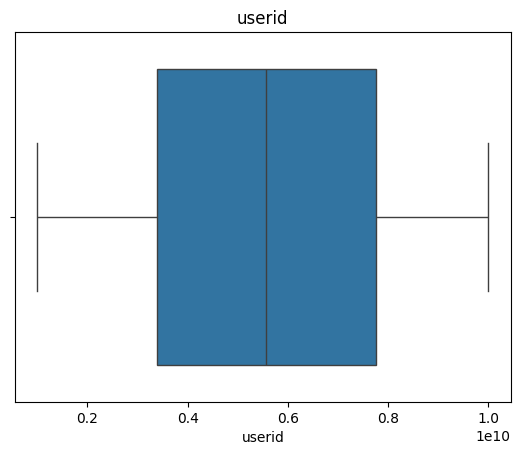

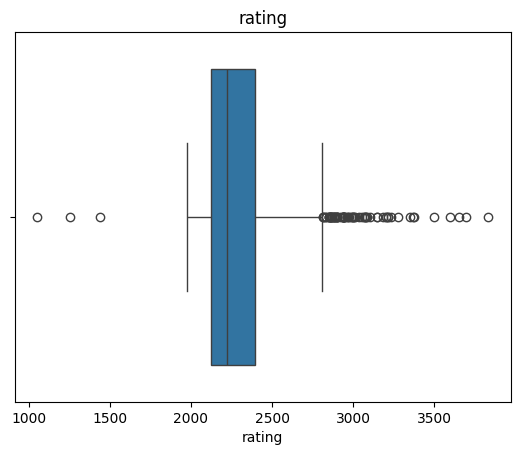

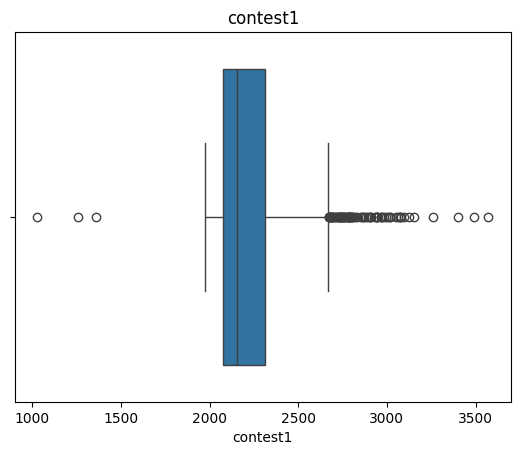

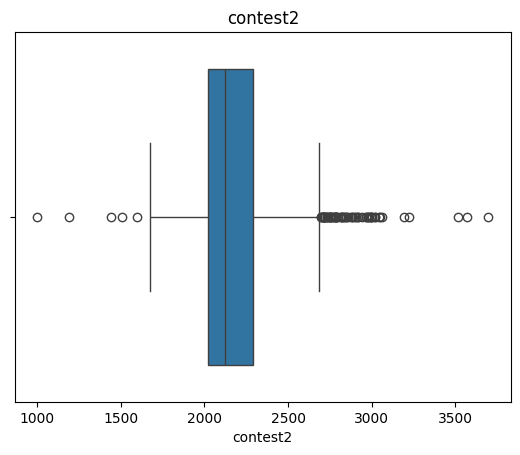

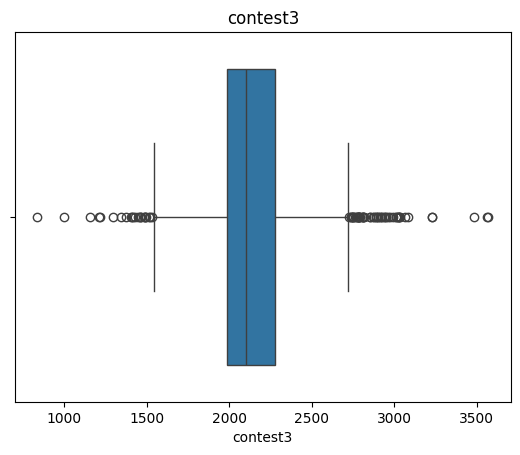

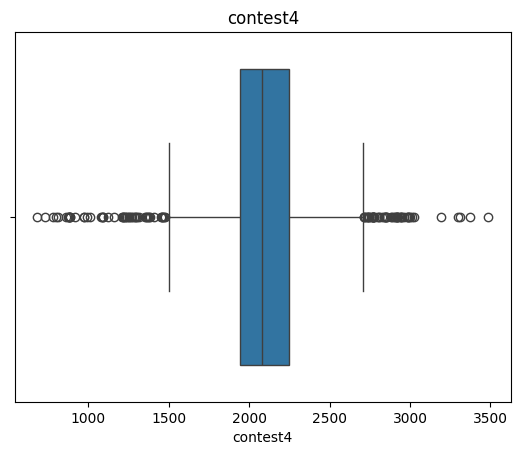

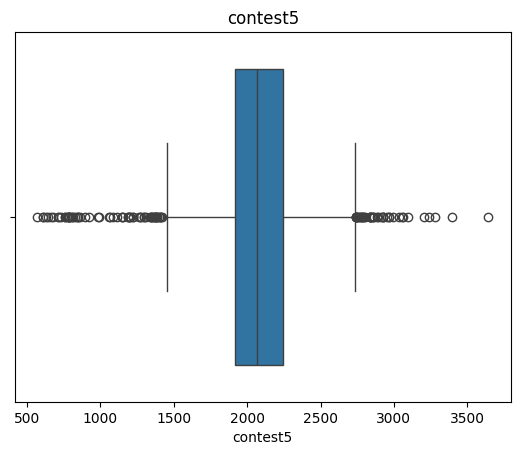

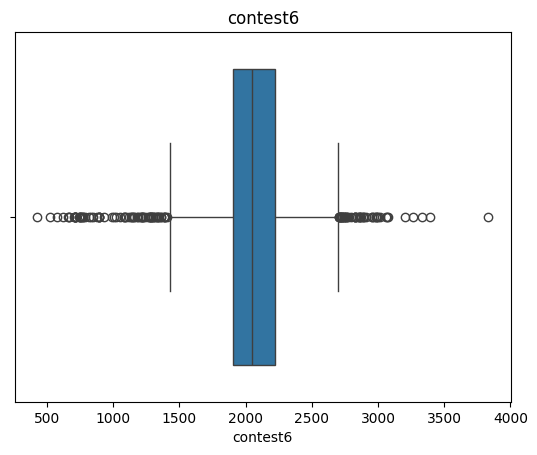

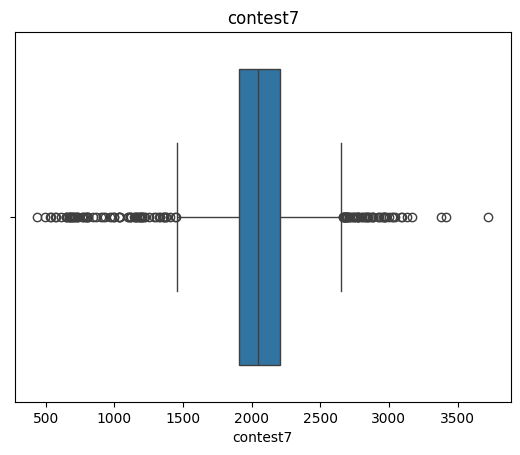

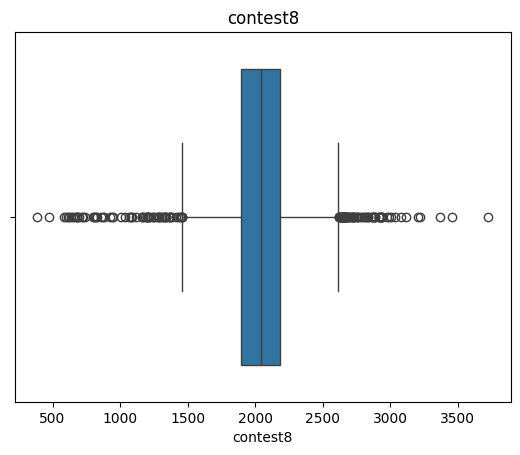

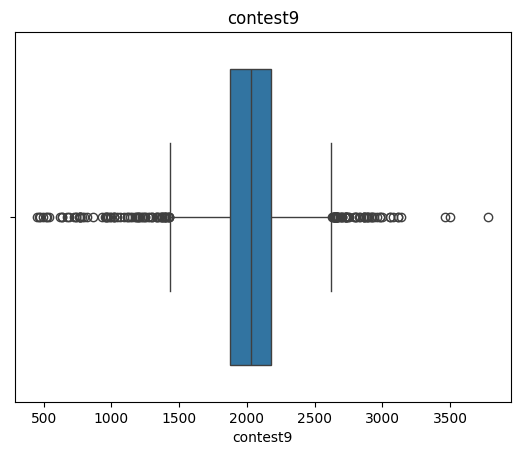

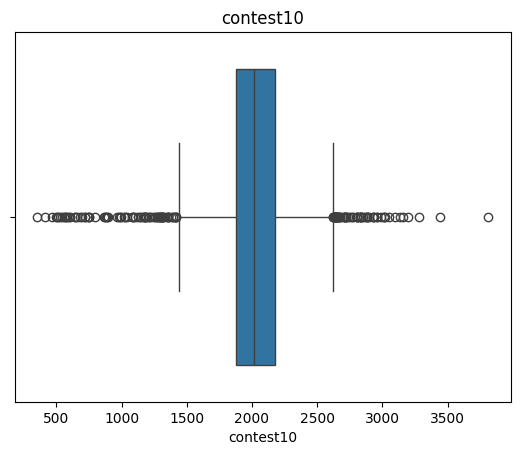

In [10]:
# Boxplots to detect outliers in all numerical columns
for col in df.select_dtypes(include=np.number).columns:
    plt.figure()
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

# **VISUALIZATION**

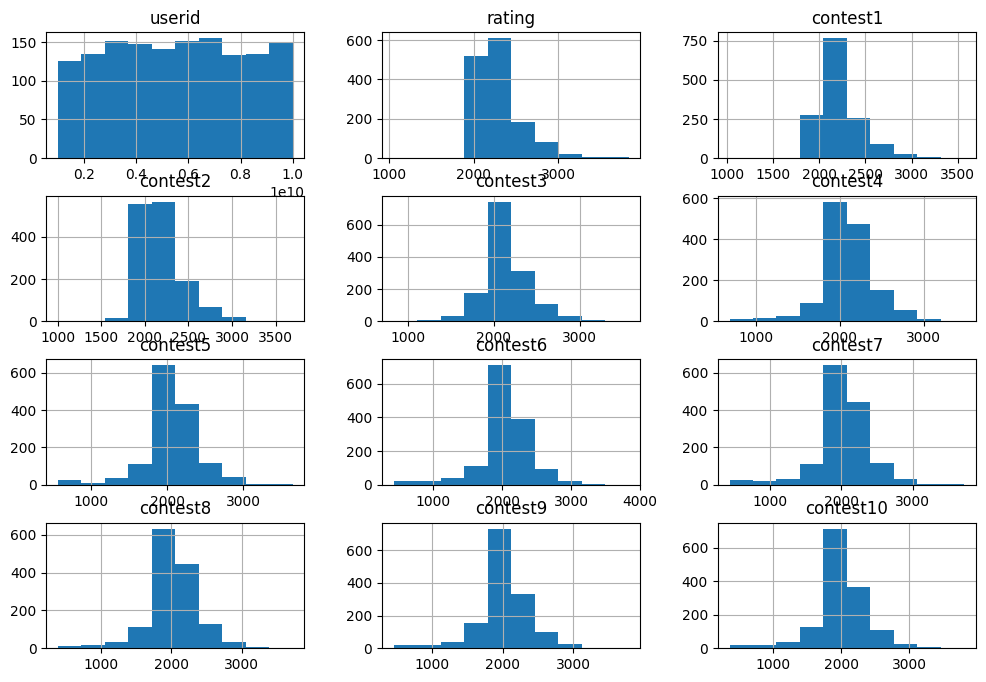

In [45]:
# Distribution
df.hist(figsize=(12,8))
plt.show()

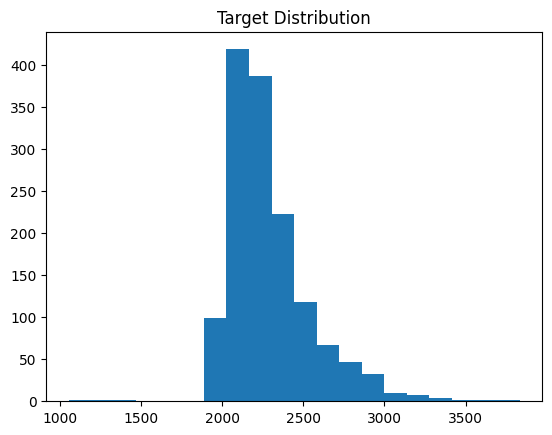

In [21]:
# Target distribution
plt.hist(y, bins=20)
plt.title("Target Distribution")
plt.show()

# **Correlation**

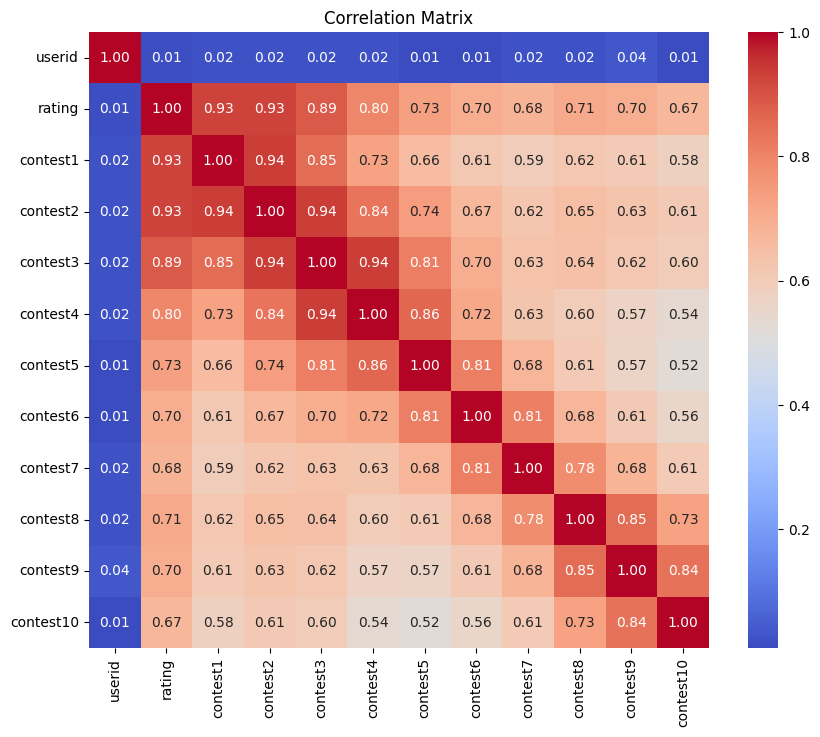

In [46]:
# Correlation heatmap
correlation_matrix = df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

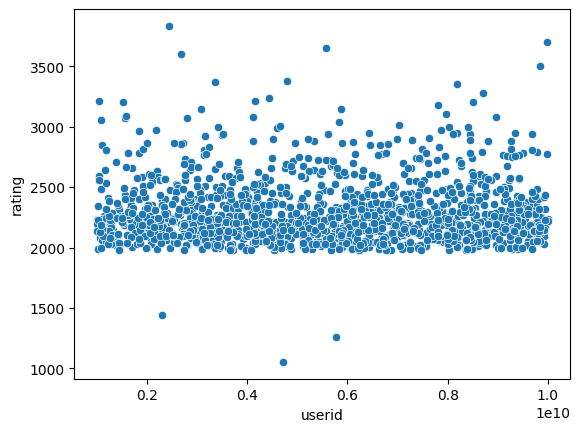

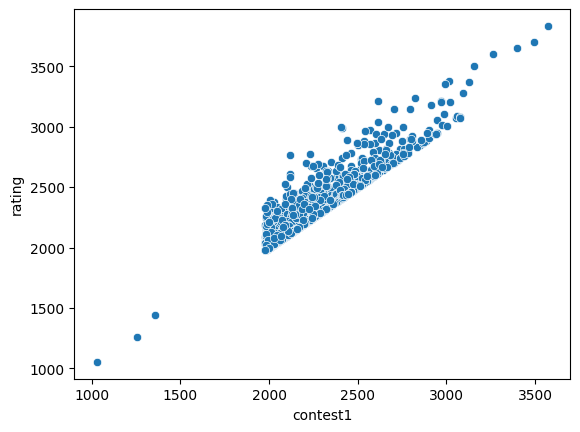

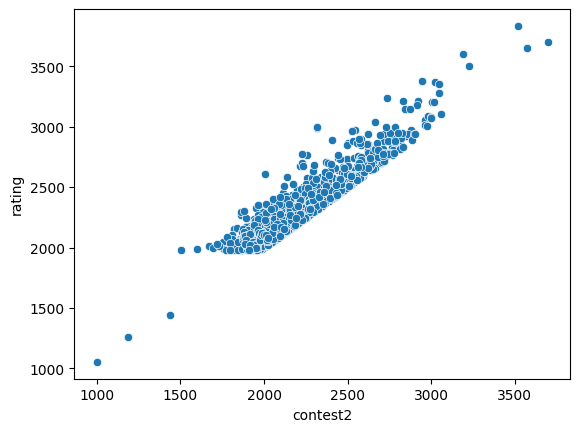

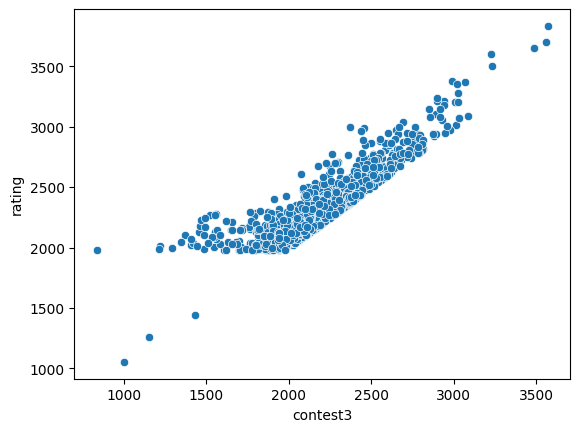

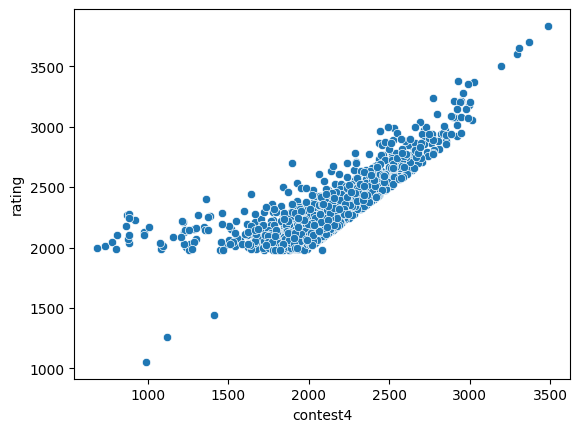

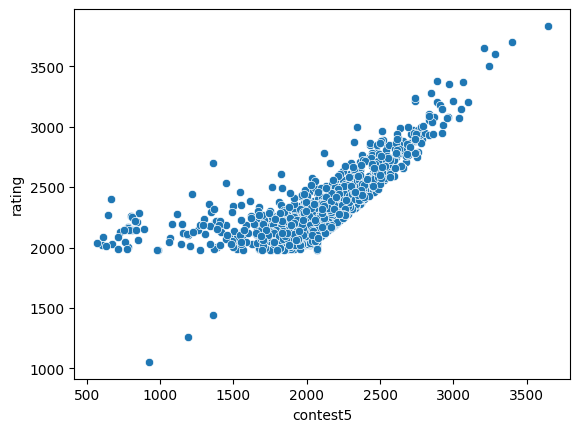

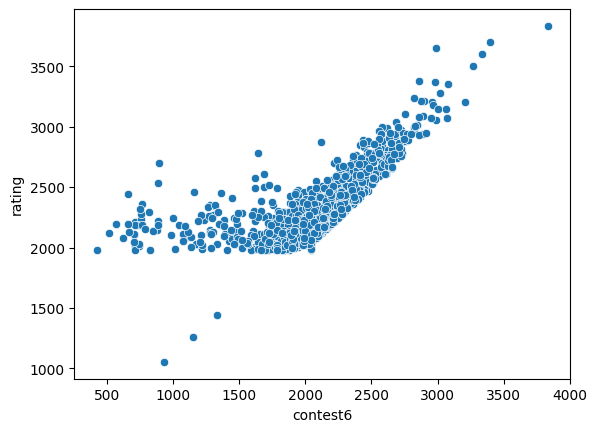

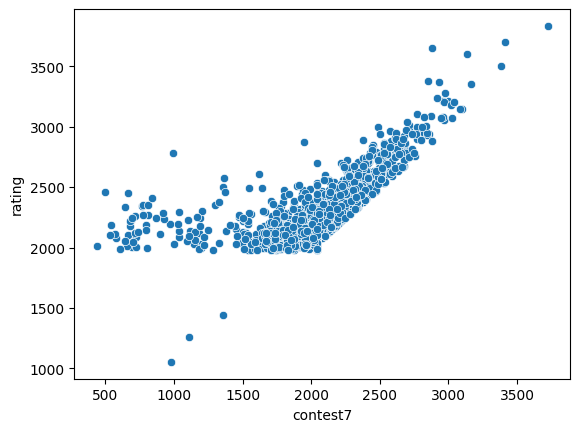

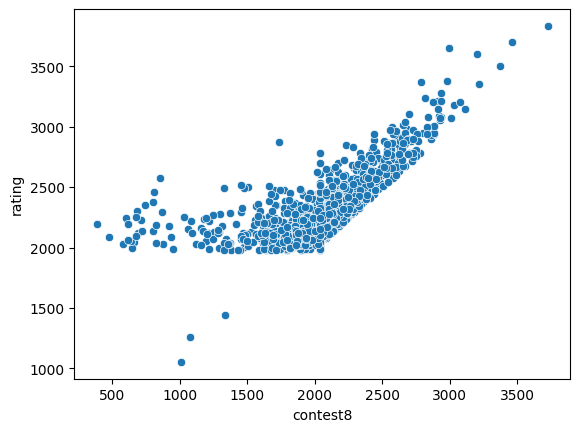

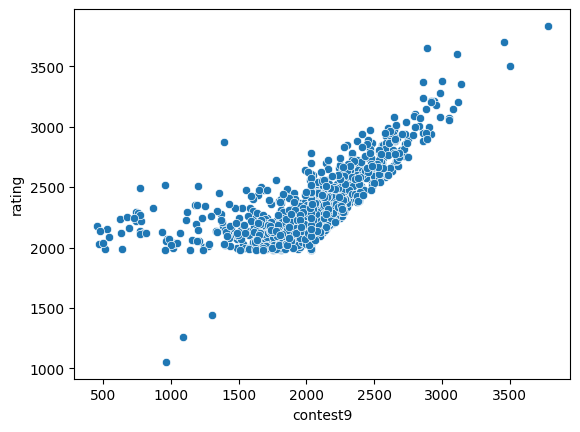

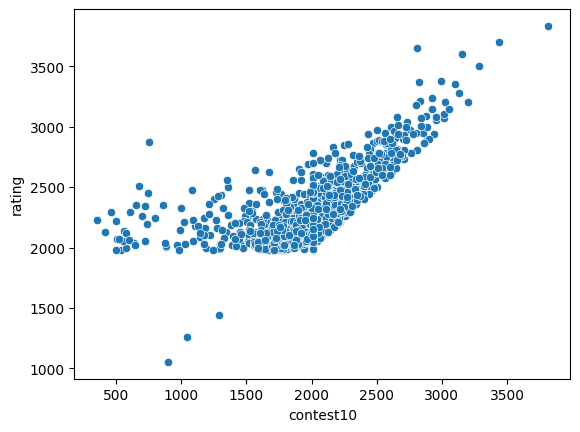

In [25]:
# Relationship between features and target
for col in df.select_dtypes(include=np.number).columns:
    if col != "rating":
        plt.figure()
        sns.scatterplot(x=df[col], y=df["rating"])
        plt.xlabel(col)
        plt.ylabel("rating")
        plt.show()

# **Train Test Split**

In [26]:
# Split features & target
X = df.drop("rating", axis=1)
y = df["rating"]
## Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [27]:
# Scaling (important for KNN & SVR)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# **MODELS TRAINING**

In [28]:
# Evaluating its performance using MAE, MSE, RMSE, and R² score
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print("Linear Regression:")
print("MAE:", mean_absolute_error(y_test, y_pred_lr))
print("MSE:", mean_squared_error(y_test, y_pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lr)))
print("R2:", r2_score(y_test, y_pred_lr))

Linear Regression:
MAE: 55.51558499336764
MSE: 5601.26249102453
RMSE: 74.8415826330826
R2: 0.9243074612956369


In [29]:
# Evaluating its performance using MAE, MSE, RMSE, and R² score
dt = DecisionTreeRegressor()
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

print("\nDecision Tree:")
print("MAE:", mean_absolute_error(y_test, y_pred_dt))
print("MSE:", mean_squared_error(y_test, y_pred_dt))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_dt)))
print("R2:", r2_score(y_test, y_pred_dt))


Decision Tree:
MAE: 56.536842105263155
MSE: 8928.01052631579
RMSE: 94.4881501899354
R2: 0.879351524161027


In [30]:
# Evaluating its performance using MAE, MSE, RMSE, and R² score
ab = AdaBoostRegressor()
ab.fit(X_train, y_train)
y_pred_ab = ab.predict(X_test)

print("\nAdaBoost:")
print("MAE:", mean_absolute_error(y_test, y_pred_ab))
print("MSE:", mean_squared_error(y_test, y_pred_ab))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_ab)))
print("R2:", r2_score(y_test, y_pred_ab))


AdaBoost:
MAE: 67.17897326638932
MSE: 6481.196126521547
RMSE: 80.5058763477645
R2: 0.9124164972729981


**`KNN`**

In [31]:
knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)

print("\nKNN Regressor")
print("MAE:", mean_absolute_error(y_test, y_pred_knn))
print("MSE:", mean_squared_error(y_test, y_pred_knn))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_knn)))
print("R2:", r2_score(y_test, y_pred_knn))


KNN Regressor
MAE: 58.1101754385965
MSE: 6747.975157894735
RMSE: 82.14605990487149
R2: 0.9088113846416789


**`SVR`**

In [32]:
svr = SVR()
svr.fit(X_train_scaled, y_train)

y_pred_svr = svr.predict(X_test_scaled)

print("\nSVR")
print("MAE:", mean_absolute_error(y_test, y_pred_svr))
print("MSE:", mean_squared_error(y_test, y_pred_svr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_svr)))
print("R2:", r2_score(y_test, y_pred_svr))


SVR
MAE: 133.04778361824594
MSE: 51625.20757382123
RMSE: 227.21181213533163
R2: 0.30236388159564853


# **MODEL EVALUATION**

In [33]:
def evaluate(model, X_test, y_test):
    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    return mae, mse, rmse, r2

# **EVALUATE ALL MODELS**

In [47]:
lr_metrics = evaluate(lr, X_test, y_test)
dt_metrics = evaluate(dt, X_test, y_test)
ada_metrics = evaluate(ab, X_test, y_test)
knn_metrics = evaluate(knn, X_test_scaled, y_test)
svr_metrics = evaluate(svr, X_test_scaled, y_test)

# **COMPARISON**

In [48]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "AdaBoost", "KNN", "SVR"],
    "MAE": [lr_metrics[0], dt_metrics[0], ada_metrics[0], knn_metrics[0], svr_metrics[0]],
    "MSE": [lr_metrics[1], dt_metrics[1], ada_metrics[1], knn_metrics[1], svr_metrics[1]],
    "RMSE": [lr_metrics[2], dt_metrics[2], ada_metrics[2], knn_metrics[2], svr_metrics[2]],
    "R2": [lr_metrics[3], dt_metrics[3], ada_metrics[3], knn_metrics[3], svr_metrics[3]]
})

results

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,55.515585,5601.262491,74.841583,0.924307
1,Decision Tree,56.536842,8928.010526,94.488150,0.879352
2,AdaBoost,67.178973,6481.196127,80.505876,0.912416
3,KNN,58.110175,6747.975158,82.146060,0.908811
4,SVR,133.047784,51625.207574,227.211812,0.302364


# **BEST MODEL**

In [36]:
results.sort_values(by="R2", ascending=False)

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,55.515585,5601.262491,74.841583,0.924307
2,AdaBoost,67.178973,6481.196127,80.505876,0.912416
3,KNN,58.110175,6747.975158,82.146060,0.908811
1,Decision Tree,56.536842,8928.010526,94.488150,0.879352
4,SVR,133.047784,51625.207574,227.211812,0.302364


# **VISUALIZATION COMPARISON**

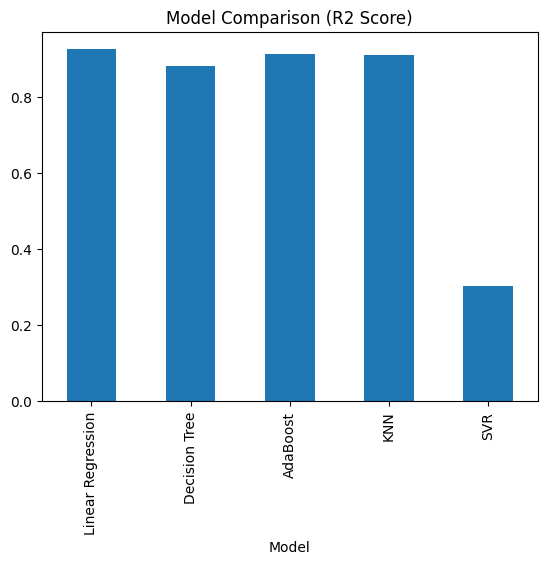

In [37]:
# R2 Comparison
results.set_index("Model")["R2"].plot(kind="bar")
plt.title("Model Comparison (R2 Score)")
plt.show()

# **Prediction vs Actual (Linear Regression example)**

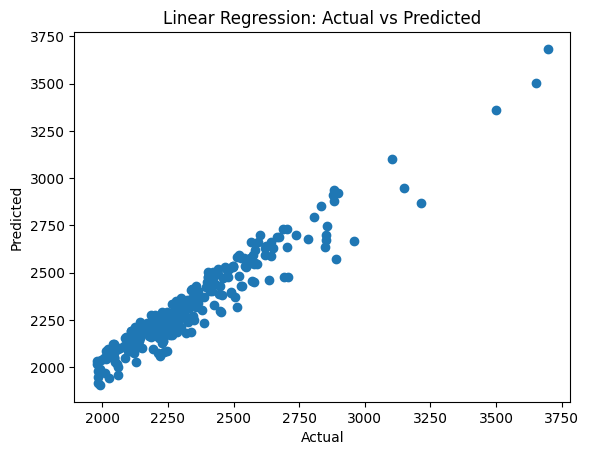

In [38]:
y_pred = lr.predict(X_test)

plt.scatter(y_test, y_pred)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Linear Regression: Actual vs Predicted")
plt.show()

In [40]:
import gradio as gr
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

# Load data
df = pd.read_csv("/content/regression_df.csv")

# Handle missing values
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

target = "rating"
X = df.drop(columns=[target])
y = df[target]

# Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Models
models = {
    "Linear Regression": LinearRegression().fit(X, y),
    "Decision Tree": DecisionTreeRegressor().fit(X, y),
    "AdaBoost": AdaBoostRegressor().fit(X, y),
    "KNN": KNeighborsRegressor().fit(X_scaled, y),
    "SVR": SVR().fit(X_scaled, y)
}

r2_scores = {
    "Linear Regression": 0.92,
    "Decision Tree": 0.88,
    "AdaBoost": 0.90,
    "KNN": 0.90,
    "SVR": 0.30
}

def predict(model_name, *inputs):
    model = models[model_name]
    input_array = np.array(inputs).reshape(1, -1)

#Scaling
    if model_name in ["KNN", "SVR"]:
        input_array = scaler.transform(input_array)

    prediction = model.predict(input_array)[0]
    r2 = r2_scores[model_name]

    return f"Prediction: {prediction:.2f}\nR² Score: {r2}"


inputs = [gr.Number(label=col) for col in X.columns]

# 🎨 Purple Dark Theme
custom_theme = gr.themes.Base()

custom_css = """
body {
    background-color: #1a1025 !important;  /* dark purple */
}

.gradio-container {
    background-color: #1a1025 !important;
    color: white !important;
}

/* inputs */
input, textarea {
    background-color: rgba(186, 104, 200, 0.2) !important; /* light purple transparent */
    border: 1px solid rgba(186, 104, 200, 0.4) !important;
    color: white !important;
    border-radius: 10px !important;
}

/* dropdown */
select {
    background-color: rgba(186, 104, 200, 0.2) !important;
    color: white !important;
}

/* buttons */
button {
    background-color: rgba(255, 255, 255, 0.15) !important; /* glass effect */
    color: white !important;
    border: 1px solid rgba(255, 255, 255, 0.3) !important;
    border-radius: 12px !important;
    backdrop-filter: blur(6px);
}

button:hover {
    background-color: rgba(255, 255, 255, 0.25) !important;
}
"""

interface = gr.Interface(
    fn=predict,
    inputs=[gr.Dropdown(list(models.keys()), label="Choose Model"), *inputs],
    outputs="text",
    title="Machine Learning Prediction System",
    description="Select model → enter values → get prediction + R² score",
    theme=custom_theme,
    css=custom_css
)

interface.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2a06581e2321b7632c.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
